# R-MOVE · 04 · ¿A qué barrios de Barcelona dejan de llegar los viajes cuando falla Rodalies?

**Respuesta corta: la caída se concentra en los barrios con estación de Rodalies, a la ida y a la vuelta. Eso confirma que es el tren.**

- **Mismo resultado que el notebook 03** (sección 1): con los datos por barrio, los dependientes caen un −8,9 % de media en los 4 días de caos (notebook 03: −6,2 %), los cercanos un −2,9 % (−2,2 %) y los que tienen metro o FGC no cambian.
- **La caída está en los barrios con estación** (sección 2): los viajes de los dependientes hacia esos barrios caen un **−14,6 %**; hacia los demás, solo un −4,5 %. Con días normales no sale nunca una diferencia así (sección 8).
- **Los cercanos también lo notan, pero solo hacia las estaciones** (sección 2): −8,4 % hacia los barrios con estación y +0,6 % hacia el resto. En el notebook 03 su caída total (−2,2 %) parece pequeña porque se diluye.
- **Con aviso, parte de la gente cambia de destino** (sección 3): en la huelga del 26/03/2025 el total no cambia (+1,8 %), pero los viajes bajan hacia los barrios con estación (−3,5 %) y suben hacia el resto (+5,8 %). El 01/04 sí hay caída (−9,4 %), concentrada en los barrios con estación.
- **Pierden más los barrios de las grandes estaciones** (sección 4): Sants, Pl. Catalunya/Pg. de Gràcia, Sant Andreu, Arc de Triomf y Estació de França, entre −15 % y −20 % de media.
- **La vuelta lo confirma** (sección 5): −14,2 % desde los barrios con estación y −0,7 % desde el resto.
- **Las averías de una línea siguen el mismo patrón** (sección 7): en Gavà (R2 Sud), −31 % hacia los barrios con estación a la ida y −62 % a la vuelta; las demás líneas no cambian.
- **La avería corta de la tarde (05/06/2025)** no cambia la ida, como en el notebook 03, pero la vuelta cae un −6,8 % (sección 6). Es un indicio, no una prueba.

## Cómo leer este notebook

**La idea.** El notebook 03 mide *cuántos* viajes a Barcelona se pierden en cada municipio. Los datos por barrio dicen
además *hacia dónde* iban y *desde dónde* se vuelve. Eso permite responder tres preguntas que el 03 no puede:

1. **¿Es el tren?** Si la caída se debe a Rodalies, tiene que concentrarse en los viajes hacia los **barrios con estación**
   (Sants, Pg. de Gràcia/Pl. Catalunya, Sant Andreu…). Si afectara a todos los barrios por igual, sería otra cosa.
2. **¿La gente deja de ir o cambia de destino?** Si el total no cambia pero bajan los barrios con estación y suben los
   demás, la gente sigue yendo a Barcelona por otro camino.
3. **¿Qué pasa a la vuelta?** Una avería por la tarde no afecta a la ida, pero puede afectar al regreso.

**Mismos días que el notebook 03.** Se leen sus exportaciones, así que los días de caos, los días limpios, los grupos
de municipios y el control son exactamente los mismos:

| Caso | Fecha | En el notebook 03 |
|---|---|---|
| 4 días de caos | 13/05/2024 (avería, robo de cobre en Montcada) y huelgas del 17/03, 26/03 y 01/04/2025 | Secciones 1–5 |
| Contraste: avería corta y por la tarde | 05/06/2025 | Sección 4.5 |
| Averías de una sola línea | 02/05/2023 (R2 Sud, Gavà) y 22/11/2024 (R4 Nord) | Sección 4.6 |

**Mismo método que el notebook 03 (clustering).** Cada día se compara con los días limpios **de su mismo tipo**
(mismo clustering, que aquí se reconstruye y se comprueba que da las mismas cifras), descontando lo que cambia el control
(municipios sin Rodalies) ese día. El margen de error y la p salen de tratar cada día limpio como un falso día de caos.
La regresión se usa como comprobación (sección 8.2).

**Única adaptación a los barrios.** El control se mide **hacia el mismo tipo de barrio**: el efecto hacia los barrios con
estación descuenta lo que cambian ese día los viajes del control hacia los barrios con estación (y lo mismo para los
barrios sin estación). Así, un día en que todo el mundo va menos al centro no se confunde con un efecto del tren.

| Si lees… | Significa… |
|---|---|
| **Ida** | Viajes de un municipio hacia un barrio de Barcelona |
| **Vuelta** | Viajes de un barrio de Barcelona hacia un municipio |
| **Con / sin estación** | Barrio de Barcelona con o sin estación de Rodalies |
| **Diferencia** | Cuánto más cambian los viajes hacia barrios con estación que hacia barrios sin estación |
| **Efecto claro** | La caída es mayor que la variación normal entre días (p < 0,05) |
| **Margen de error** | Rango donde está el efecto real con un 95 % de seguridad. Si cruza el 0, no es concluyente |

**Estructura**

| Parte | Contenido |
|---|---|
| **A. Preparación** | Datos por barrios, objetos del notebook 03, barrios con estación y herramientas de cálculo |
| **1–7. Resultados** | Coherencia con el 03 → con/sin estación → día a día → barrios y líneas → vuelta → contraste → averías de una línea |
| **8. ¿Es real o casualidad?** | Prueba del día falso y comprobación con la regresión |
| **9. Conclusiones** | |
| **B. Anexo técnico** | Método, decisiones sobre los datos, limitaciones y exportación para el dashboard |

---
# A. Preparación de los datos

*Esta parte prepara todo lo necesario para los resultados. No hace falta leerla para entenderlos.*

### A.1 Configuración

In [1]:
import json
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyfixest as pf
from sklearn.cluster import KMeans
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
RAW = ROOT / "data" / "raw" / "telefonica"
OUT = ROOT / "data" / "processed" / "rmove"
BCN = "08019"
K_VOL = 4                       # tipos de día del clustering, como en el notebook 03

# Casos del notebook 03 que no están en sus exportaciones (mismos valores que allí)
CASO_CONTRASTE = ("2025-06-05", "Avería: tren detenido entre Pl. Catalunya y Bif. Vilanova (14:25–16:14)")
R4_NORD = {"Montcada i Reixac", "Cerdanyola del Vallès", "Barberà del Vallès", "Sabadell", "Terrassa",
           "Viladecavalls", "Vacarisses", "Castellbell i el Vilar", "Sant Vicenç de Castellet", "Manresa", "Rajadell"}

### A.2 Datos por barrios

Ficheros `movilidad_mun_barrios_*_origen.csv` de Telefónica, segmentos **Regional + Residente** (como en el notebook 03).
Se construyen dos tablas: la **ida** (municipio → barrio de Barcelona) y la **vuelta** (barrio de Barcelona → municipio).
Las filas repetidas de cada día, municipio y barrio se **suman** (notebook 01, sección 3). Si las tablas ya existen, solo se leen.

In [2]:
F_IDA = OUT / "movilidad_municipio_a_barrio.parquet"
F_VUELTA = OUT / "movilidad_barrio_a_municipio.parquet"
CSV = f"read_csv('{RAW.as_posix()}/*/movilidad_mun_barrios_*_origen.csv', union_by_name=true, " \
      "types={'municipio_origen':'VARCHAR','municipio_destino':'VARCHAR','barrio_origen':'VARCHAR','barrio_destino':'VARCHAR'})"

if not F_IDA.exists():
    duckdb.connect().execute(f"""
    COPY (SELECT CAST(day AS DATE) AS fecha, municipio_origen, barrio_destino,
                 any_value(barrio_destino_name) AS barrio, SUM(viajes) AS viajes
          FROM {CSV}
          WHERE municipio_destino = '{BCN}' AND origen IN ('Regional', 'Residente')
          GROUP BY 1, 2, 3 HAVING SUM(viajes) > 0) TO '{F_IDA.as_posix()}' (FORMAT parquet)""")
if not F_VUELTA.exists():
    duckdb.connect().execute(f"""
    COPY (SELECT CAST(day AS DATE) AS fecha,
                 municipio_destino AS municipio_origen,          -- municipio al que se vuelve
                 barrio_origen AS barrio_destino,                -- barrio de Barcelona desde el que se sale
                 any_value(barrio_origen_name) AS barrio, SUM(viajes) AS viajes
          FROM {CSV}
          WHERE municipio_origen = '{BCN}' AND municipio_destino <> '{BCN}' AND origen IN ('Regional', 'Residente')
          GROUP BY 1, 2, 3 HAVING SUM(viajes) > 0) TO '{F_VUELTA.as_posix()}' (FORMAT parquet)""")

ida, vuelta = pd.read_parquet(F_IDA), pd.read_parquet(F_VUELTA)
for t in (ida, vuelta):
    t["fecha"] = pd.to_datetime(t.fecha)
print(f"Ida: {len(ida):,} filas · Vuelta: {len(vuelta):,} filas · {ida.fecha.nunique()} días · "
      f"{ida.municipio_origen.nunique()} municipios · {ida.barrio_destino.nunique()} barrios")

Ida: 3,059,153 filas · Vuelta: 3,094,274 filas · 971 días · 302 municipios · 73 barrios


### A.3 Objetos del notebook 03

Calendario de días limpios, días de caos, averías de una línea, grupos de municipios, control, volumen del control
(variable del clustering) y panel de viajes por municipio.

In [3]:
cal = pd.read_parquet(OUT / "municipios_calendario.parquet")
info = pd.read_parquet(OUT / "municipios_info.parquet")
caos_real = pd.DatetimeIndex(pd.read_parquet(OUT / "municipios_dias_caos.parquet").fecha)
averias = pd.read_parquet(OUT / "municipios_averias_linea.parquet")
vol_ctrl = pd.read_parquet(OUT / "municipios_volumen_control.parquet").vol_ctrl
V = pd.read_parquet(OUT / "municipios_panel_viajes.parquet")              # viajes por municipio (notebook 03)
CTRL = list(pd.read_parquet(OUT / "municipios_control.parquet").municipio_code)
d_contraste = pd.Timestamp(CASO_CONTRASTE[0])
limpios = cal.index[cal.limpio]

GRUPOS = {"Dependientes (≥20 km, sin metro/FGC)": list(info.index[info.dependiente]),
          "Cercanos sin metro/FGC (<20 km)": list(info.index[info.grupo == "Cercano sin metro/FGC"]),
          "Con metro/FGC": list(info.index[info.con_alt])}
DEP = GRUPOS["Dependientes (≥20 km, sin metro/FGC)"]

print("Días de caos:", ", ".join(f"{d:%d/%m/%Y}" for d in caos_real))
print("Averías de una línea:", ", ".join(f"{r.fecha:%d/%m/%Y} ({r.linea})" for r in averias.itertuples()))
print("Contraste:", f"{d_contraste:%d/%m/%Y}", "· días limpios:", len(limpios))
print({g: len(c) for g, c in GRUPOS.items()} | {"Control (sin Rodalies)": len(CTRL)})

# Coherencia: viajes por barrio sumados por municipio frente a los viajes por municipio, en los días limpios
a = ida[ida.fecha.isin(limpios)].groupby("municipio_origen").viajes.sum()
b = V.loc[V.index.isin(limpios)].sum()
j = pd.concat([a.rename("barrios"), b.rename("municipios")], axis=1).dropna()
print(f"\nDatos por barrios / por municipios (mismos {len(j)} municipios, días limpios): {j.barrios.sum() / j.municipios.sum():.2f}"
      f" · correlación entre municipios (log): {np.corrcoef(np.log(j.barrios), np.log(j.municipios))[0, 1]:.3f}")

Días de caos: 13/05/2024, 17/03/2025, 26/03/2025, 01/04/2025
Averías de una línea: 02/05/2023 (R2S), 22/11/2024 (R4N)
Contraste: 05/06/2025 · días limpios: 273
{'Dependientes (≥20 km, sin metro/FGC)': 35, 'Cercanos sin metro/FGC (<20 km)': 16, 'Con metro/FGC': 11, 'Control (sin Rodalies)': 71}



Datos por barrios / por municipios (mismos 133 municipios, días limpios): 0.88 · correlación entre municipios (log): 0.990


**Resultado.** Los días, los grupos y el control son los del notebook 03: 4 días de caos, 2 averías de una línea, el contraste del 05/06/2025 y 273 días limpios; 35 municipios dependientes, 16 cercanos sin metro/FGC, 11 con metro/FGC y 71 de control. En los días limpios, los datos por barrio suman ≈ el **88 %** de los viajes por municipio, con una correlación de **0,99** entre municipios: son coherentes, aunque pierden los flujos pequeños (al repartir por barrios hay más ceros por privacidad).

### A.4 Barrios con estación de Rodalies

Cada estación de Barcelona se asigna al barrio de su punto central (`bcn_station_neighborhoods.json`). Las líneas de
cada barrio se fijan a mano según la red de 2023–2025, porque el GTFS es del horario actual.

In [4]:
J = json.load(open(next(ROOT.rglob("bcn_station_neighborhoods.json")), encoding="utf-8"))
est = pd.read_csv(OUT / "estaciones_rodalies_municipio.csv", dtype={"stop_id": str})
est_bcn = (pd.DataFrame([{"stop_id": c["station_id"], "barrio": c["respuesta"]["resultats"][0]["nom"]}
                         for c in J["consultas"] if c["dx_m"] == 0 and c["dy_m"] == 0])
           .merge(est[["stop_id", "stop_name"]], on="stop_id", how="left"))

LINEAS_BARRIO = {
    "Sants": "R1,R2N,R2S,R3,R4",
    "la Dreta de l'Eixample": "R1,R2N,R2S,R3,R4",      # Pl. Catalunya + Pg. de Gràcia
    "el Fort Pienc": "R1,R3,R4",                       # Arc de Triomf
    "el Clot": "R1,R2N",
    "Sant Andreu": "R2N,R3,R4,R7",                     # Sant Andreu + Fabra i Puig
    "Sant Pere, Santa Caterina i la Ribera": "R2N,R2S",  # Estació de França
    "la Sagrera": "R3,R4,R7",
    "Torre Baró": "R3,R4,R7",
}
barrios = ida.groupby("barrio_destino").barrio.first().to_frame()
barrios["con_estacion"] = barrios.barrio.isin(est_bcn.barrio)
barrios["lineas"] = barrios.barrio.map(LINEAS_BARRIO)
barrios["estaciones"] = barrios.barrio.map(est_bcn.groupby("barrio").stop_name.apply(
    lambda s: ", ".join(x.replace("Barcelona", "").strip(" -") for x in s)))
barrios["viajes_dia_dependientes"] = (ida[ida.fecha.isin(limpios) & ida.municipio_origen.isin(DEP)]
                                      .groupby("barrio_destino").viajes.sum() / len(limpios)).round()
CON = list(barrios.index[barrios.con_estacion])
SIN = list(barrios.index[~barrios.con_estacion])

con_est = barrios[barrios.con_estacion].sort_values("viajes_dia_dependientes", ascending=False)
display(con_est[["barrio", "estaciones", "lineas", "viajes_dia_dependientes"]])
print(f"{len(CON)} barrios con estación de {len(barrios)} · reciben el "
      f"{con_est.viajes_dia_dependientes.sum() / barrios.viajes_dia_dependientes.sum():.0%} de los viajes de los dependientes")

,barrio,estaciones,lineas,viajes_dia_dependientes
barrio_destino,,,,
080190203,la Dreta de l'Eixample,"Plaça de Catalunya, Passeig de Gràcia","R1,R2N,R2S,R3,R4",8463.0
080190308,Sants,Sants,"R1,R2N,R2S,R3,R4",5455.0
080190904,Sant Andreu,"Sant Andreu, Fabra i Puig","R2N,R3,R4,R7",3249.0
080190201,el Fort Pienc,Arc de Triomf,"R1,R3,R4",959.0
080190104,"Sant Pere, Santa Caterina i la Ribera",Estació de França,"R2N,R2S",580.0
080190905,la Sagrera,La Sagrera-Meridiana,"R3,R4,R7",421.0
080191002,el Clot,El Clot,"R1,R2N",259.0
080190811,Torre Baró,Torre Baró -Vallbona,"R3,R4,R7",37.0


8 barrios con estación de 73 · reciben el 38% de los viajes de los dependientes


**Resultado.** Hay **8 barrios con estación** de los 73. Reciben el **38 %** de los viajes de los municipios dependientes, sobre todo la Dreta de l'Eixample (Pl. Catalunya y Pg. de Gràcia, ≈ 8.500 viajes al día), Sants (≈ 5.500) y Sant Andreu (≈ 3.200). Torre Baró recibe muy pocos (≈ 40 al día).

### A.5 Herramientas de cálculo

**Clustering (igual que el notebook 03).** Se reconstruyen los tipos de día y los placebos con las mismas variables,
el mismo algoritmo y la misma semilla, y se comprueba que dan las mismas cifras que el notebook 03.

In [5]:
def variables_dia(dias):
    """Variables del clustering: log del volumen de los municipios sin Rodalies y época del año."""
    dias = pd.DatetimeIndex(dias)
    return pd.DataFrame({"vol": vol_ctrl.reindex(dias).values, "epoca": dias.day_of_year / 365}, index=dias)


def ajustar_tipos(dias):
    return make_pipeline(StandardScaler(), KMeans(K_VOL, n_init=10, random_state=0)).fit(variables_dia(dias))


modelos = {}
for y in sorted(cal.index.year.unique()):
    dias = limpios[limpios.year == y].intersection(vol_ctrl.dropna().index)
    if len(dias) < 2 * K_VOL:
        continue
    pipe = ajustar_tipos(dias)
    centros = pipe[0].inverse_transform(pipe[-1].cluster_centers_)
    nombre = {c: "ABCD"[i] for i, c in enumerate(np.argsort(centros[:, 1]))}
    modelos[y] = (pipe, nombre, pd.Series([nombre[c] for c in pipe[-1].labels_], index=dias))


def dias_mismo_tipo(d):
    """Días limpios del mismo año y del mismo tipo que d."""
    pipe, nombre, tipos = modelos[d.year]
    return tipos.index[tipos == nombre[pipe.predict(variables_dia([d]))[0]]]


# Placebos: cada día limpio como falso día de caos, con el clustering reentrenado sin él
REF_LOO = {}
for y, (_, _, tipos) in modelos.items():
    for d in tipos.index:
        resto = tipos.index.drop(d)
        p_ = ajustar_tipos(resto)
        REF_LOO[d] = resto[p_[-1].labels_ == p_.predict(variables_dia([d]))[0]]
print(f"{len(REF_LOO)} días limpios con placebo (notebook 03: 272)")

272 días limpios con placebo (notebook 03: 272)


**Efecto.** Para un grupo de municipios y un conjunto de barrios de destino:

$$\text{efecto}_d = \frac{\text{viajes del grupo}_d \,/\, \text{mediana en los días del mismo tipo}}
{\text{viajes del control}_d \,/\, \text{mediana en los días del mismo tipo}} - 1$$

donde los viajes del grupo y del control se cuentan **hacia los mismos barrios**. Con todos los barrios es exactamente el
efecto del notebook 03 (calculado con los datos por barrio); con los barrios con estación, el efecto hacia ellos, y así.
La **diferencia** entre barrios con y sin estación se calcula igual, día a día, y su p sale de los mismos placebos.

In [6]:
DIAS = V.index          # días del panel del notebook 03: limpios, de caos, contraste y averías de una línea
_pct = lambda x: (np.exp(x) - 1) * 100


def matriz(df):
    """Viajes por día × (barrio, municipio), solo en los días del panel."""
    d = df[df.fecha.isin(DIAS)]
    return d.pivot_table(index="fecha", columns=["barrio_destino", "municipio_origen"], values="viajes", aggfunc="sum")


M = {"ida": matriz(ida), "vuelta": matriz(vuelta)}


def serie(sentido, codes, destinos=None):
    """Viajes diarios de los municipios `codes` hacia (ida) o desde (vuelta) los barrios `destinos` (todos si None)."""
    m = M[sentido]
    cols = m.columns[m.columns.get_level_values(1).isin(codes)]
    if destinos is not None:
        cols = cols[cols.get_level_values(0).isin(destinos)]
    return m[cols].sum(axis=1, min_count=1).reindex(DIAS)


def _ef_log(s, sc, d, ref):
    """Efecto (en log) del día d frente a los días ref, corregido por el control (como en el notebook 03)."""
    return np.log(s.loc[d] / s.loc[ref].median()) - np.log(sc.loc[d] / sc.loc[ref].median())


def efectos(sentido, codes, dias, destinos=None):
    """Efecto (log) de cada día analizado y de cada placebo, con el control hacia los mismos barrios."""
    s, sc = serie(sentido, codes, destinos), serie(sentido, CTRL, destinos)
    obs = np.array([_ef_log(s, sc, d, dias_mismo_tipo(d)) for d in dias])
    plac = np.array([_ef_log(s, sc, d, ref) for d, ref in REF_LOO.items()])
    return obs, plac


def resumen(obs, plac, n_sim=20000, seed=0):
    """Efecto %, p, IC95 a partir de los placebos (mismo cálculo que el notebook 03)."""
    obs, plac = obs[np.isfinite(obs)], plac[np.isfinite(plac)]
    if len(obs) == 0:
        return {"cambio_%": np.nan, "lo": np.nan, "hi": np.nan, "p": np.nan}
    o = obs.mean()
    dist = plac if len(obs) == 1 else np.random.default_rng(seed).choice(plac, (n_sim, len(obs))).mean(axis=1)
    return {"cambio_%": round(_pct(o), 1), "lo": round(_pct(o - np.quantile(dist, .975)), 1),
            "hi": round(_pct(o - np.quantile(dist, .025)), 1), "p": round((1 + (dist <= o).sum()) / (len(dist) + 1), 3)}


def con_sin(sentido, codes, dias, con=None, sin=None):
    """Efecto total, hacia barrios con estación, hacia barrios sin estación y diferencia (con − sin)."""
    con, sin = CON if con is None else con, SIN if sin is None else sin
    oc, pc = efectos(sentido, codes, dias, con)
    os_, ps = efectos(sentido, codes, dias, sin)
    return {"Total": resumen(*efectos(sentido, codes, dias)), "Con estación": resumen(oc, pc),
            "Sin estación": resumen(os_, ps), "Diferencia": resumen(oc - os_, pc - ps)}


def tabla(casos, sentido="ida"):
    """casos: {nombre: (municipios, días)} → una fila por caso y columnas por destino."""
    filas = []
    for nombre, (codes, dias) in casos.items():
        r = con_sin(sentido, codes, pd.DatetimeIndex(dias))
        fila = {"caso": nombre, "municipios": len(codes)}
        for k, v in r.items():
            fila |= {f"{k} %": v["cambio_%"], f"{k} p": v["p"]}
        fila |= {"Con estación lo": r["Con estación"]["lo"], "Con estación hi": r["Con estación"]["hi"],
                 "Sin estación lo": r["Sin estación"]["lo"], "Sin estación hi": r["Sin estación"]["hi"]}
        filas.append(fila)
    return pd.DataFrame(filas).set_index("caso")


VISTA = ["municipios", "Total %", "Total p", "Con estación %", "Con estación p", "Sin estación %", "Sin estación p",
         "Diferencia %", "Diferencia p"]

# Comprobación: con el panel por municipio del notebook 03, el método da sus mismas cifras
s_ctrl_mun = V[CTRL].sum(axis=1, min_count=1)


def efecto_municipios(codes, dias):
    s = V[[c for c in codes if c in V.columns]].sum(axis=1, min_count=1)
    obs = np.array([_ef_log(s, s_ctrl_mun, d, dias_mismo_tipo(d)) for d in dias])
    plac = np.array([_ef_log(s, s_ctrl_mun, d, ref) for d, ref in REF_LOO.items()])
    return resumen(obs, plac)


print("Dependientes, media de los 4 días de caos (notebook 03: −6,2 % [−8,8, −3,3]):", efecto_municipios(DEP, caos_real))

Dependientes, media de los 4 días de caos (notebook 03: −6,2 % [−8,8, −3,3]): {'cambio_%': np.float64(-6.2), 'lo': np.float64(-8.8), 'hi': np.float64(-3.3), 'p': np.float64(0.0)}


In [7]:
from matplotlib.lines import Line2D

ROJO, AZUL, GRIS = "#C0392B", "#2E6DA4", "0.6"
ETQ = {pd.Timestamp("2024-05-13"): "13/05/24\nAvería", pd.Timestamp("2025-03-17"): "17/03/25\nHuelga",
       pd.Timestamp("2025-03-26"): "26/03/25\nHuelga", pd.Timestamp("2025-04-01"): "01/04/25\nHuelga"}


def grafico_con_sin(t, titulo, etiquetas=None):
    """Para cada caso: efecto hacia barrios con estación (rojo) y sin estación (azul), con su margen de error."""
    t = t.iloc[::-1]
    y = np.arange(len(t))
    fig, ax = plt.subplots(figsize=(10, 0.8 * len(t) + 1.6))
    ax.axvline(0, color="black", lw=.8)
    for k, col, dy in [("Con estación", ROJO, .15), ("Sin estación", AZUL, -.15)]:
        claro = t[f"{k} p"] < 0.05
        ax.hlines(y + dy, t[f"{k} lo"], t[f"{k} hi"], color=col, lw=4, alpha=.3)
        ax.scatter(t[f"{k} %"], y + dy, color=np.where(claro, col, "white"), edgecolor=col, s=70, zorder=3)
        for yi, (v, hi) in enumerate(zip(t[f"{k} %"], t[f"{k} hi"])):
            ax.text(hi + .6, yi + dy, f"{v:+.1f} %".replace(".", ","), va="center", fontsize=8, color=col)
    ax.set_yticks(y, etiquetas[::-1] if etiquetas else t.index)
    ax.set_xlabel("Cambio en los viajes respecto a lo esperado (%) · punto lleno = efecto claro (p < 0,05)")
    ax.set_title(titulo, loc="left", fontweight="bold")
    marcas = [Line2D([], [], marker="o", ls="", color=c, markersize=8, label=f"Barrios {k}")
              for c, k in [(ROJO, "con estación"), (AZUL, "sin estación")]]
    ax.legend(handles=marcas, frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
    ax.spines[["top", "right", "left"]].set_visible(False)
    plt.tight_layout()
    plt.show()

---
# Resultados

## 1. ¿Los datos por barrios dan el mismo resultado que el notebook 03?

Se suman todos los barrios de cada municipio y se repite el cálculo del notebook 03 con los mismos grupos y los mismos
días. La primera columna es el notebook 03 (viajes por municipio); la segunda, los datos por barrio.

In [8]:
filas = []
for g, codes in GRUPOS.items():
    for nombre, dias in [("Media de los 4 días", caos_real)] + [(f"{d:%d/%m/%Y}", [d]) for d in caos_real]:
        m = efecto_municipios(codes, pd.DatetimeIndex(dias))
        b = resumen(*efectos("ida", codes, pd.DatetimeIndex(dias)))
        filas.append({"grupo": g, "caso": nombre, "notebook 03 %": m["cambio_%"], "notebook 03 p": m["p"],
                      "por barrios %": b["cambio_%"], "por barrios p": b["p"]})
coherencia = pd.DataFrame(filas).set_index(["grupo", "caso"])
display(coherencia)

notebook 03 %  \
grupo                                caso                                 
Dependientes (≥20 km, sin metro/FGC) Media de los 4 días           -6.2   
                                     13/05/2024                   -10.3   
                                     17/03/2025                    -8.9   
                                     26/03/2025                     1.8   
                                     01/04/2025                    -6.8   
Cercanos sin metro/FGC (<20 km)      Media de los 4 días           -2.2   
                                     13/05/2024                    -0.4   
                                     17/03/2025                    -0.1   
                                     26/03/2025                    -4.0   
                                     01/04/2025                    -4.4   
Con metro/FGC                        Media de los 4 días           -1.0   
                                     13/05/2024                     4.2   
                                     17/03/2025                    -0.1   
                                     26/03/2025                    -4.3   
                                     01/04/2025                    -3.8   

                                                          notebook 03 p  \
grupo                                caso                                 
Dependientes (≥20 km, sin metro/FGC) Media de los 4 días          0.000   
                                     13/05/2024                   0.007   
                                     17/03/2025                   0.011   
                                     26/03/2025                   0.711   
                                     01/04/2025                   0.022   
Cercanos sin metro/FGC (<20 km)      Media de los 4 días          0.018   
                                     13/05/2024                   0.440   
                                     17/03/2025                   0.484   
                                     26/03/2025                   0.029   
                                     01/04/2025                   0.015   
Con metro/FGC                        Media de los 4 días          0.071   
                                     13/05/2024                   0.974   
                                     17/03/2025                   0.476   
                                     26/03/2025                   0.007   
                                     01/04/2025                   0.007   

                                                          por barrios %  \
grupo                                caso                                 
Dependientes (≥20 km, sin metro/FGC) Media de los 4 días           -8.9   
                                     13/05/2024                   -14.5   
                                     17/03/2025                   -12.8   
                                     26/03/2025                     1.8   
                                     01/04/2025                    -9.4   
Cercanos sin metro/FGC (<20 km)      Media de los 4 días           -2.9   
                                     13/05/2024                    -1.1   
                                     17/03/2025                    -0.3   
                                     26/03/2025                    -4.7   
                                     01/04/2025                    -5.4   
Con metro/FGC                        Media de los 4 días           -1.3   
                                     13/05/2024                     3.7   
                                     17/03/2025                    -0.0   
                                     26/03/2025                    -4.7   
                                     01/04/2025                    -4.0   

                                                          por barrios p  
grupo                                caso                                
Dependientes (≥20 km, sin metro/FGC) Media de los 4 días          0.000  
        

**Resultado.** Con los mismos municipios, los datos por barrio dan **el mismo patrón y la misma significancia** que el notebook 03, en la media y día a día: los dependientes caen claramente el 13/05, el 17/03 y el 01/04, y no el 26/03; los cercanos caen un poco, sobre todo en las huelgas del 26/03 y el 01/04; los que tienen metro o FGC no cambian en la media.

| Media de los 4 días | Notebook 03 | Por barrios |
|---|---|---|
| Dependientes | −6,2 % | −8,9 % |
| Cercanos sin metro/FGC | −2,2 % | −2,9 % |
| Con metro/FGC | −1,0 % | −1,3 % |

Las caídas por barrio son algo mayores, probablemente por composición: estos datos pierden los flujos pequeños, y los grandes van sobre todo a los barrios con estación, que son los que más caen (sección 2). Por eso se interpretan sobre todo la dirección y las comparaciones entre barrios.

## 2. ¿La caída se concentra en los barrios con estación?

Media de los 4 días de caos, para cada grupo: efecto hacia los barrios con estación, hacia los barrios sin estación y la
diferencia entre los dos.

,municipios,Total %,Total p,Con estación %,Con estación p,Sin estación %,Sin estación p,Diferencia %,Diferencia p
caso,,,,,,,,,
"Dependientes (≥20 km, sin metro/FGC)",35,-8.9,0.000,-14.6,0.000,-4.5,0.049,-10.6,0.000
Cercanos sin metro/FGC (<20 km),16,-2.9,0.012,-8.4,0.000,0.6,0.664,-8.9,0.000
Con metro/FGC,11,-1.3,0.064,-1.7,0.146,-0.6,0.317,-1.1,0.275


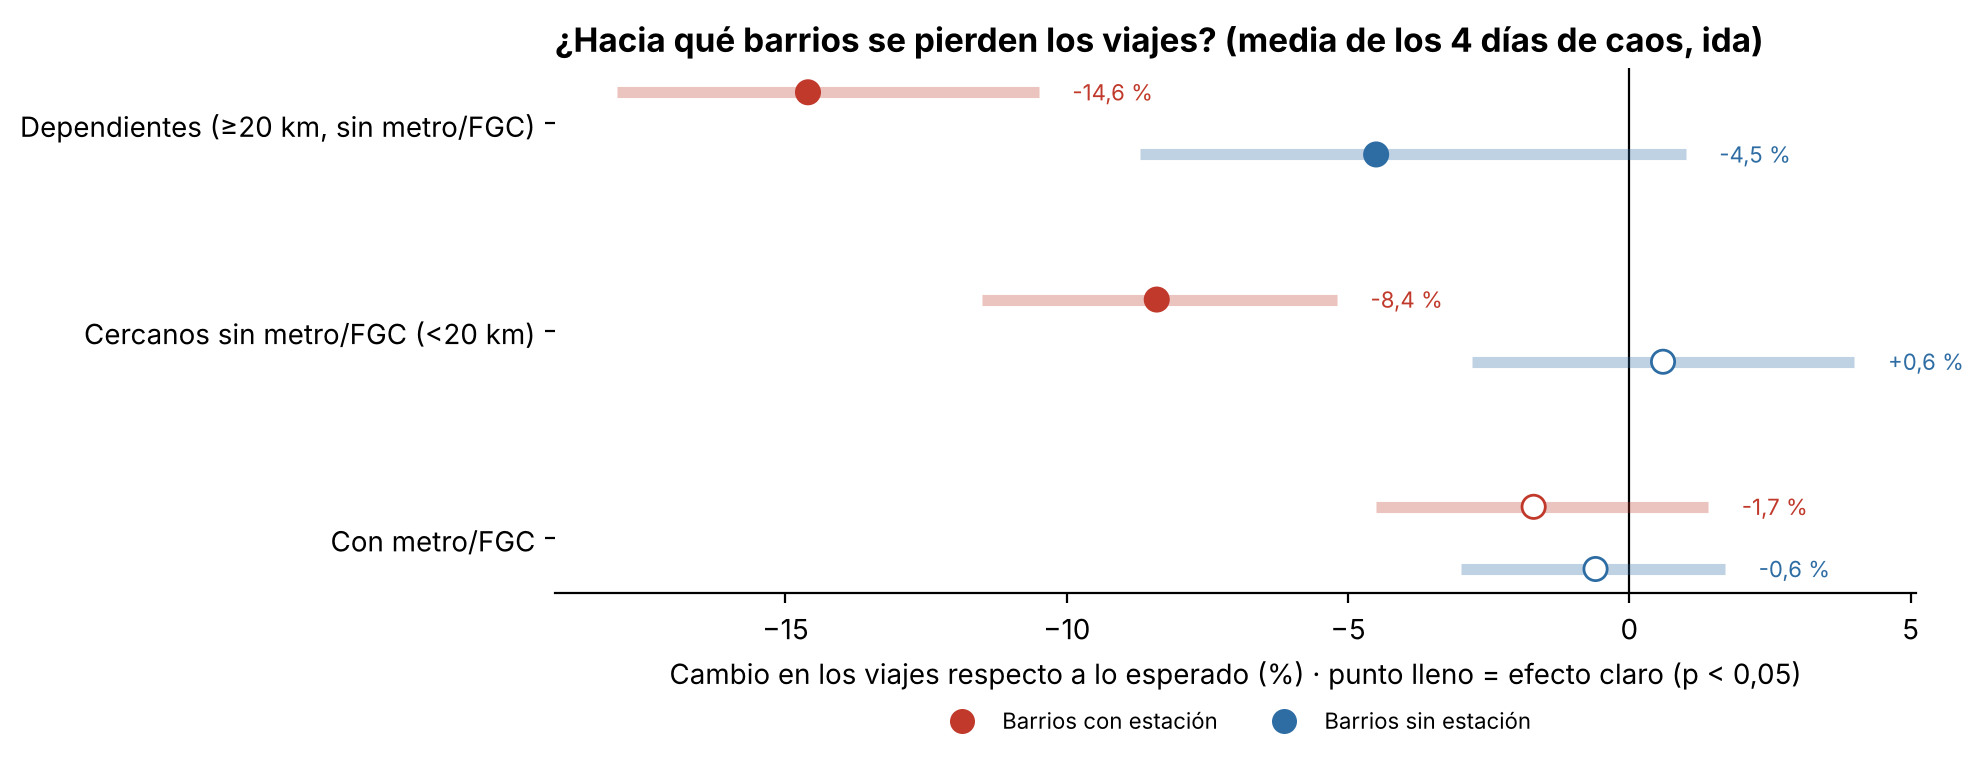

In [9]:
res_grupos = tabla({g: (codes, caos_real) for g, codes in GRUPOS.items()})
display(res_grupos[VISTA])
grafico_con_sin(res_grupos, "¿Hacia qué barrios se pierden los viajes? (media de los 4 días de caos, ida)")

**Resultado.** **Sí: la caída se concentra en los barrios con estación.**
- **Dependientes:** −14,6 % hacia los barrios con estación (margen de error [−18,0, −10,5]) frente a −4,5 % hacia el resto (p = 0,049, justo en el límite). La diferencia, −10,6 %, es clara (p < 0,001).
- **Cercanos sin metro/FGC:** −8,4 % hacia los barrios con estación y +0,6 % hacia el resto. Su pequeña caída total del notebook 03 (−2,2 %) es en realidad una caída clara de los viajes que van a las estaciones, diluida entre todos los demás.
- **Con metro/FGC:** no cambian hacia ningún tipo de barrio.

**Lectura.** Si la caída se debiera a otra cosa (el tiempo, un día flojo), afectaría a todos los barrios por igual. Que se concentre en los barrios a los que se llega en Rodalies indica que el efecto es del tren.

## 3. Día a día: ¿qué cambia cuando la incidencia se anuncia?

Solo los municipios dependientes. La avería del 13/05/2024 fue por sorpresa; las huelgas se conocían con días de antelación.

,municipios,Total %,Total p,Con estación %,Con estación p,Sin estación %,Sin estación p,Diferencia %,Diferencia p
caso,,,,,,,,,
13/05/2024,35,-14.5,0.007,-24.0,0.004,-8.6,0.051,-16.9,0.011
17/03/2025,35,-12.8,0.011,-14.9,0.007,-9.5,0.044,-6.0,0.176
26/03/2025,35,1.8,0.652,-3.5,0.205,5.8,0.894,-8.8,0.044
01/04/2025,35,-9.4,0.018,-14.7,0.007,-4.9,0.147,-10.3,0.029


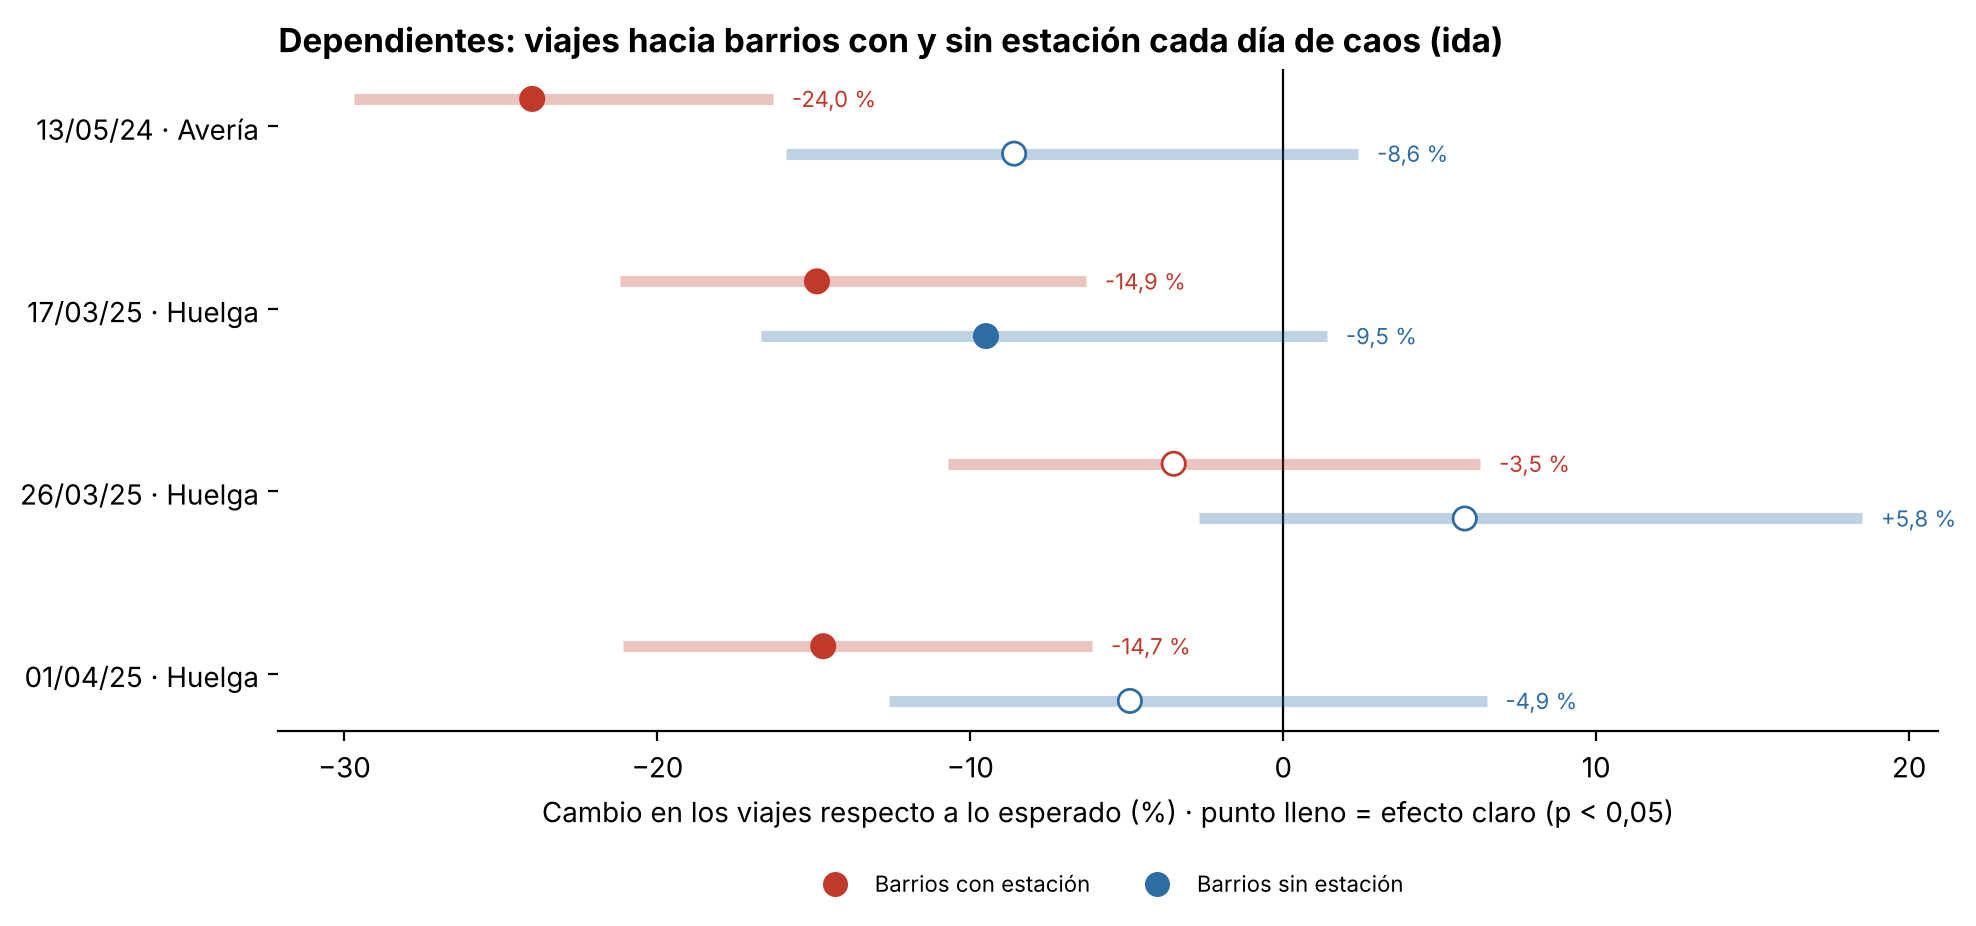

In [10]:
res_dias = tabla({f"{d:%d/%m/%Y}": (DEP, [d]) for d in caos_real})
display(res_dias[VISTA])
grafico_con_sin(res_dias, "Dependientes: viajes hacia barrios con y sin estación cada día de caos (ida)",
                [ETQ[d].replace("\n", " · ") for d in caos_real])

**Resultado.**

| Dependientes · ida | Total | Con estación | Sin estación | Diferencia |
|---|---|---|---|---|
| 13/05/2024 · avería | −14,5 % | −24,0 % | −8,6 % | −16,9 % (p = 0,01) |
| 17/03/2025 · huelga | −12,8 % | −14,9 % | −9,5 % | −6,0 % (p = 0,18) |
| 26/03/2025 · huelga | +1,8 % | −3,5 % | +5,8 % | −8,8 % (p = 0,04) |
| 01/04/2025 · huelga | −9,4 % | −14,7 % | −4,9 % | −10,3 % (p = 0,03) |

- **Avería por sorpresa (13/05):** la caída más fuerte, y muy concentrada en los barrios con estación (−24 %).
- **Huelga general (17/03):** también caen claramente los viajes hacia los barrios sin estación (−9,5 %, p = 0,04): la huelga afectó a más viajes que los que van a las estaciones, y la diferencia entre los dos tipos de barrio no es clara.
- **Huelga del 26/03:** **el total no cambia, pero sí el destino**: menos viajes hacia los barrios con estación y más hacia el resto. Quien sabía que había huelga siguió yendo a Barcelona por otro camino. El notebook 03, que solo ve el total, no puede ver esto.
- **Huelga del 01/04:** a pesar del aviso, hay una caída clara (−9,4 %), concentrada en los barrios con estación.

## 4. ¿Qué barrios y qué líneas?

### 4.1 Los barrios con estación, uno a uno

Efecto de los dependientes hacia cada barrio con estación (media de los 4 días de caos y los dos días más fuertes).
Los barrios con pocos viajes desde los dependientes tienen márgenes de error muy amplios.

In [11]:
filas = []
for b in con_est.index:                        # barrios con estación, de más a menos viajes
    fila = {"barrio": barrios.at[b, "barrio"], "líneas": barrios.at[b, "lineas"],
            "viajes/día (dependientes)": barrios.at[b, "viajes_dia_dependientes"]}
    for nombre, dias in [("media", caos_real), ("13/05/2024", ["2024-05-13"]), ("17/03/2025", ["2025-03-17"])]:
        r = resumen(*efectos("ida", DEP, pd.DatetimeIndex(dias), [b]))
        fila |= {f"{nombre} %": r["cambio_%"], f"{nombre} p": r["p"]}
    filas.append(fila)
res_barrio = pd.DataFrame(filas).set_index("barrio")
display(res_barrio)

,líneas,viajes/día (dependientes),media %,media p,13/05/2024 %,13/05/2024 p,17/03/2025 %,17/03/2025 p
barrio,,,,,,,,
la Dreta de l'Eixample,"R1,R2N,R2S,R3,R4",8463.0,-14.9,0.000,-21.6,0.004,-20.5,0.004
Sants,"R1,R2N,R2S,R3,R4",5455.0,-19.2,0.000,-27.4,0.007,-16.7,0.018
Sant Andreu,"R2N,R3,R4,R7",3249.0,-16.8,0.023,-46.0,0.011,-1.7,0.414
el Fort Pienc,"R1,R3,R4",959.0,-19.6,0.001,-26.2,0.022,-2.4,0.429
"Sant Pere, Santa Caterina i la Ribera","R2N,R2S",580.0,-18.1,0.024,-20.8,0.117,-11.8,0.275
la Sagrera,"R3,R4,R7",421.0,-5.8,0.283,48.7,0.952,-37.9,0.026
el Clot,"R1,R2N",259.0,1.4,0.578,40.8,0.901,46.3,0.912
Torre Baró,"R3,R4,R7",37.0,-28.1,0.162,-61.6,0.088,-61.0,0.092


**Resultado.** En la media de los días de caos caen claramente los cinco barrios con estación que más viajes reciben de los dependientes: el Fort Pienc / Arc de Triomf (−19,6 %), Sants (−19,2 %), Sant Pere–Santa Caterina–la Ribera / Estació de França (−18,1 %), Sant Andreu (−16,8 %) y la Dreta de l'Eixample / Pl. Catalunya y Pg. de Gràcia (−14,9 %). La Sagrera, el Clot y Torre Baró reciben pocos viajes de los dependientes (menos de 450 al día) y no dan un resultado claro.
- **13/05/2024:** caen Sant Andreu (−46 %), Sants (−27 %), el Fort Pienc (−26 %) y la Dreta de l'Eixample (−22 %).
- **17/03/2025:** caen la Dreta de l'Eixample (−21 %), Sants (−17 %) y la Sagrera (−38 %); Sant Andreu y el Fort Pienc, apenas.

### 4.2 La avería del 13/05/2024: ¿caen los barrios de la línea cortada?

El robo de cobre de Montcada cortó la R1 (Maresme). Se comparan los dependientes **de la R1** hacia los barrios con
estación de la R1, hacia los barrios con estación de otras líneas y hacia los barrios sin estación.

In [12]:
DEP_R1 = [c for c in DEP if "R1" in info.at[c, "lineas"].split("+")]
destinos_r1 = {"Barrios con estación de la R1": [b for b in CON if "R1" in barrios.at[b, "lineas"].split(",")],
               "Barrios con estación de otras líneas": [b for b in CON if "R1" not in barrios.at[b, "lineas"].split(",")],
               "Barrios sin estación": SIN}
d13 = pd.DatetimeIndex(["2024-05-13"])
res_r1 = pd.DataFrame({k: resumen(*efectos("ida", DEP_R1, d13, v)) | {"barrios": len(v)}
                       for k, v in destinos_r1.items()}).T
print(f"Dependientes de la R1: {len(DEP_R1)} municipios")
display(res_r1)

Dependientes de la R1: 12 municipios


,cambio_%,lo,hi,p,barrios
Barrios con estación de la R1,-29.3,-37.0,-19.7,0.004,4.0
Barrios con estación de otras líneas,-57.9,-69.2,-39.1,0.015,4.0
Barrios sin estación,-6.0,-14.9,12.1,0.172,65.0


**Resultado.** Los dependientes de la R1 caen un **−29 %** hacia los barrios con estación de la R1 (p < 0,01) y un **−58 %** hacia los de otras líneas (p = 0,02), mientras que hacia los barrios sin estación no hay un cambio claro (−6 %). La caída hacia otras líneas es sobre todo **Sant Andreu** (de ≈ 1.340 viajes en un día normal a ≈ 590): desde el Maresme se llega haciendo transbordo a líneas que ese día también estaban afectadas por el robo de Montcada (en el notebook 03, la R3 cae un −28 %). Son pocos viajes (≈ 1.600 al día hacia esos barrios), así que la cifra es poco precisa.

## 5. La vuelta: barrio de Barcelona → municipio

Comprobación independiente con otros viajes: si la gente no llega en tren, tampoco vuelve desde los barrios con estación.

,municipios,Total %,Total p,Con estación %,Con estación p,Sin estación %,Sin estación p,Diferencia %,Diferencia p
caso,,,,,,,,,
Media de los 4 días,35,-5.8,0.000,-14.2,0.000,-0.7,0.338,-13.6,0.000
13/05/2024,35,-12.1,0.004,-21.9,0.004,-5.0,0.099,-17.7,0.004
17/03/2025,35,-6.3,0.029,-15.2,0.004,-0.8,0.454,-14.6,0.007
26/03/2025,35,-0.5,0.487,-7.4,0.044,3.4,0.751,-10.5,0.018
01/04/2025,35,-4.0,0.132,-11.8,0.004,-0.2,0.498,-11.6,0.015


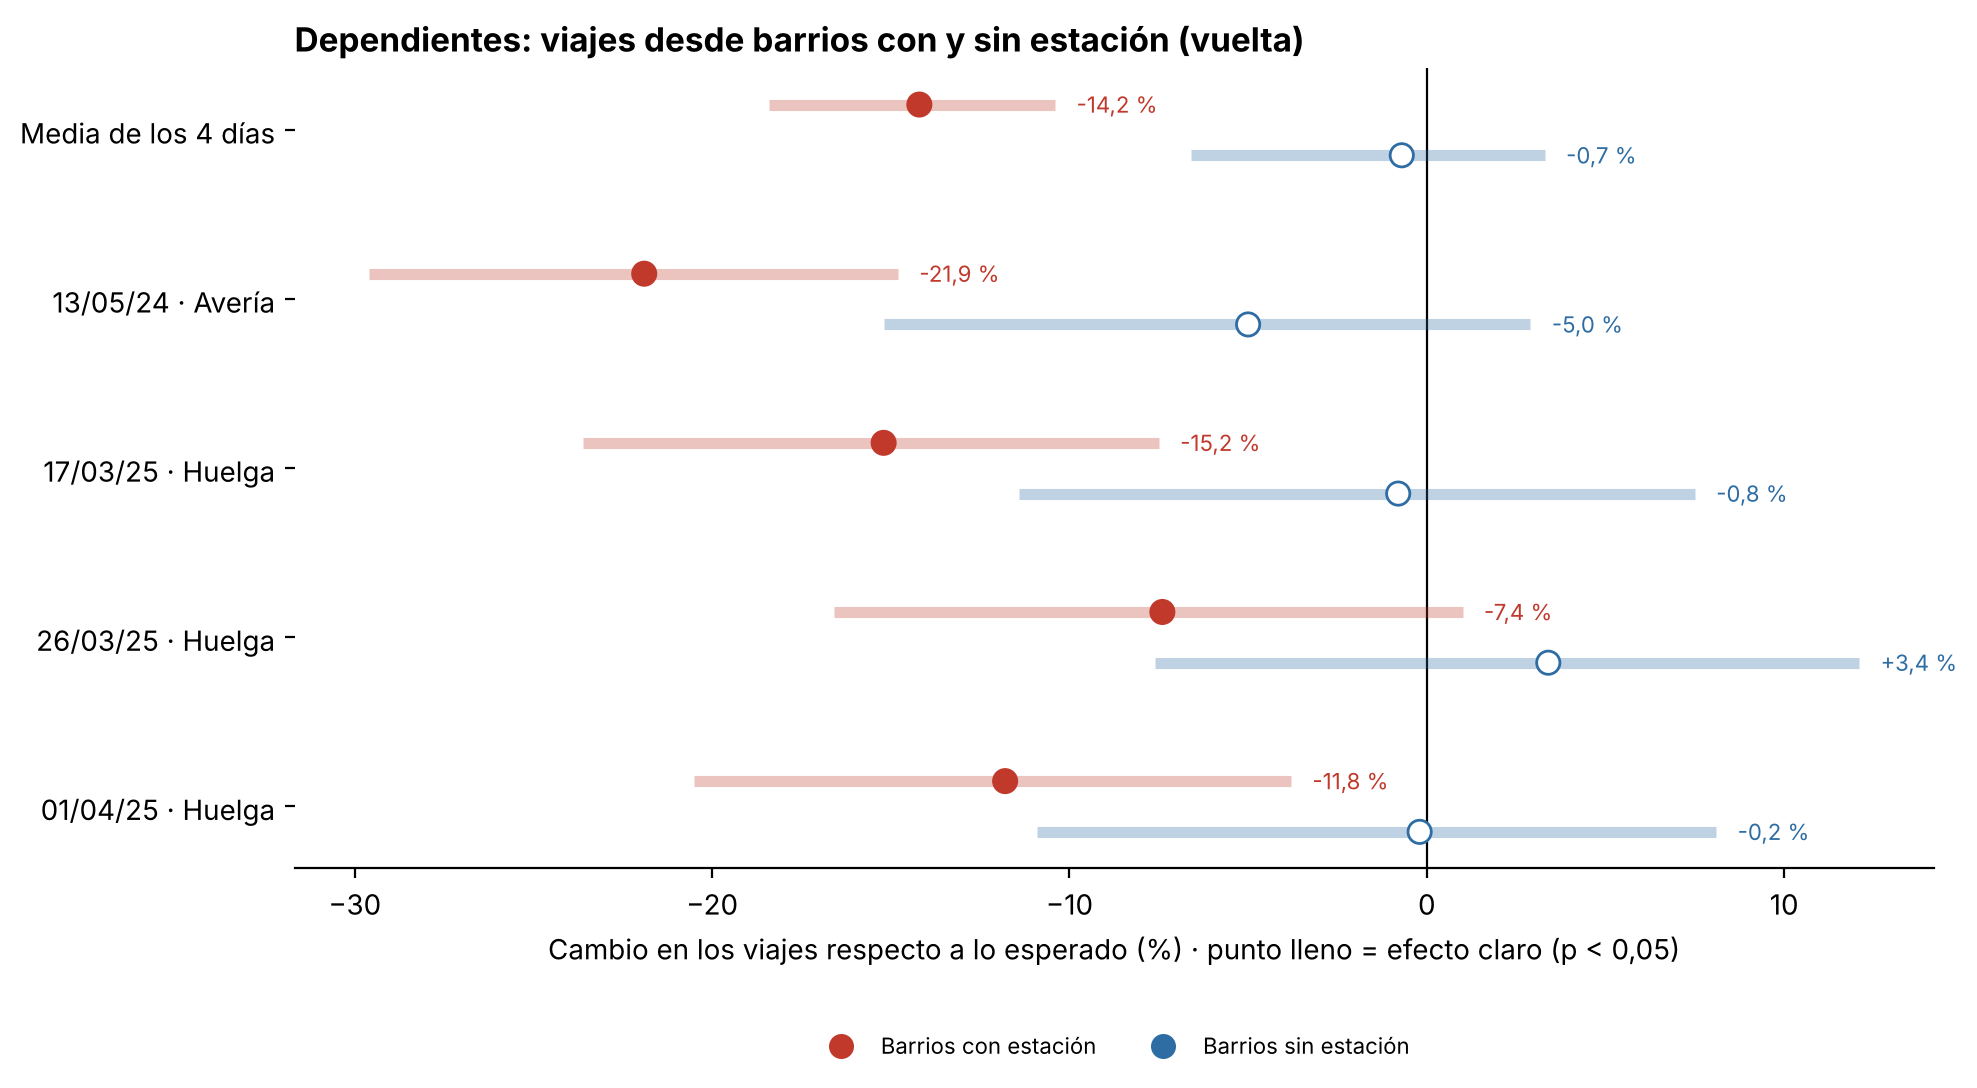

In [13]:
res_vuelta = tabla({"Media de los 4 días": (DEP, caos_real)} | {f"{d:%d/%m/%Y}": (DEP, [d]) for d in caos_real},
                   sentido="vuelta")
display(res_vuelta[VISTA])
grafico_con_sin(res_vuelta, "Dependientes: viajes desde barrios con y sin estación (vuelta)",
                ["Media de los 4 días"] + [ETQ[d].replace("\n", " · ") for d in caos_real])

**Resultado.** **La vuelta confirma la ida:** los dependientes vuelven menos desde los barrios con estación (−14,2 % de media, claro los cuatro días) y no cambian desde el resto (−0,7 %). La diferencia es clara los cuatro días, también el 26/03 (−10,5 %, p = 0,02), cuando el total no cambia: la redistribución de la huelga anunciada se ve también a la vuelta.

## 6. Contraste: una avería grande pero corta y por la tarde (05/06/2025)

En el notebook 03 (sección 4.5) este día no cambia los viajes a Barcelona: la avería fue entre las 14:25 y las 16:14,
cuando la mayoría ya había llegado. Con los datos por barrio se puede ver lo que el 03 no ve: **la vuelta**.

In [14]:
res_contraste = pd.concat({s: tabla({"Dependientes": (DEP, [d_contraste]),
                                     "Cercanos sin metro/FGC": (GRUPOS["Cercanos sin metro/FGC (<20 km)"], [d_contraste])},
                                    sentido=s)[VISTA] for s in ("ida", "vuelta")})
display(res_contraste)

municipios  Total %  Total p  Con estación %  \
       caso                                                                   
ida    Dependientes                    35      1.2    0.608            -2.0   
       Cercanos sin metro/FGC          16     -1.1    0.370            -3.5   
vuelta Dependientes                    35     -6.8    0.022            -7.9   
       Cercanos sin metro/FGC          16     -2.2    0.194            -2.8   

                               Con estación p  Sin estación %  Sin estación p  \
       caso                                                                     
ida    Dependientes                     0.315             2.0           0.630   
       Cercanos sin metro/FGC           0.150             0.0           0.549   
vuelta Dependientes                     0.037            -5.8           0.066   
       Cercanos sin metro/FGC           0.183            -1.2           0.374   

                               Diferencia %  Diferencia p  
       caso                                                
ida    Dependientes                    -3.9         0.245  
       Cercanos sin metro/FGC          -3.5         0.212  
vuelta Dependientes                    -2.2         0.311  
       Cercanos sin metro/FGC          -1.6         0.293

**Resultado.**
- **Ida:** sin cambio (dependientes +1,2 %), como en el notebook 03 (0,0 %).
- **Vuelta:** los dependientes vuelven **un −6,8 % menos** (p = 0,02), tanto desde los barrios con estación (−7,9 %) como desde el resto (−5,8 %, al límite). Los cercanos no cambian.

**Lectura.** Encaja con una avería que empezó a las 14:25, cuando la gente ya estaba en Barcelona: no afecta a la ida y sí a la vuelta. Pero es un **indicio, no una prueba**: la caída no se concentra en los barrios con estación (la diferencia no es clara) y es una sola comparación entre muchas.

## 7. Averías de una sola línea

Las dos averías de la sección 4.6 del notebook 03, con los mismos municipios: **solo los dependientes de la línea
afectada** (la R4 se separa en Nord y Sud). Como comprobación, los dependientes de las demás líneas, que funcionaban.

In [15]:
def lineas_dep(c):
    ls = set(info.at[c, "lineas"].split("+"))
    if "R4" in ls:
        ls = (ls - {"R4"}) | {"R4N" if info.at[c, "municipio"] in R4_NORD else "R4S"}
    return ls


casos_av, etiquetas_av = {}, {}
for r in averias.itertuples():
    afect = [c for c in DEP if r.linea in lineas_dep(c)]
    resto = [c for c in DEP if r.linea not in lineas_dep(c)]
    casos_av[f"{r.fecha:%d/%m/%Y} · {r.linea} · afectados"] = (afect, [r.fecha])
    casos_av[f"{r.fecha:%d/%m/%Y} · {r.linea} · demás líneas"] = (resto, [r.fecha])
res_averias = {s: tabla(casos_av, sentido=s) for s in ("ida", "vuelta")}
display(pd.concat({s: t[VISTA] for s, t in res_averias.items()}))

municipios  Total %  Total p  \
       caso                                                            
ida    02/05/2023 · R2S · afectados              4    -14.8    0.022   
       02/05/2023 · R2S · demás líneas          31     -2.3    0.326   
       22/11/2024 · R4N · afectados              4    -41.7    0.004   
       22/11/2024 · R4N · demás líneas          31     -3.9    0.139   
vuelta 02/05/2023 · R2S · afectados              4    -19.8    0.004   
       02/05/2023 · R2S · demás líneas          31      1.7    0.652   
       22/11/2024 · R4N · afectados              4     29.3    0.839   
       22/11/2024 · R4N · demás líneas          31      0.0    0.516   

                                        Con estación %  Con estación p  \
       caso                                                              
ida    02/05/2023 · R2S · afectados              -31.1           0.004   
       02/05/2023 · R2S · demás líneas             0.7           0.546   
       22/11/2024 · R4N · afectados              -73.1           0.004   
       22/11/2024 · R4N · demás líneas            -0.2           0.462   
vuelta 02/05/2023 · R2S · afectados              -62.4           0.004   
       02/05/2023 · R2S · demás líneas             3.8           0.780   
       22/11/2024 · R4N · afectados               20.6           0.769   
       22/11/2024 · R4N · demás líneas             4.2           0.824   

                                        Sin estación %  Sin estación p  \
       caso                                                              
ida    02/05/2023 · R2S · afectados               -6.9           0.132   
       02/05/2023 · R2S · demás líneas            -2.8           0.348   
       22/11/2024 · R4N · afectados              -14.2           0.253   
       22/11/2024 · R4N · demás líneas            -4.1           0.194   
vuelta 02/05/2023 · R2S · afectados                0.4           0.575   
       02/05/2023 · R2S · demás líneas             2.3           0.656   
       22/11/2024 · R4N · afectados               49.9           0.901   
       22/11/2024 · R4N · demás líneas            -0.6           0.451   

                                        Diferencia %  Diferencia p  
       caso                                                         
ida    02/05/2023 · R2S · afectados            -26.0         0.004  
       02/05/2023 · R2S · demás líneas           3.7         0.722  
       22/11/2024 · R4N · afectados            -68.7         0.007  
       22/11/2024 · R4N · demás líneas           4.1         0.769  
vuelta 02/05/2023 · R2S · afectados            -62.6         0.004  
       02/05/2023 · R2S · demás líneas           1.4         0.601  
       22/11/2024 · R4N · afectados            -19.5         0.278  
       22/11/2024 · R4N · demás líneas           4.8         0.894

**Resultado.**

| Ida · dependientes de la línea afectada | Municipios | Total | Con estación | Sin estación |
|---|---|---|---|---|
| 02/05/2023 · R2 Sud (Gavà) | 4 | −14,8 % | −31,1 % | −6,9 % |
| 22/11/2024 · R4 Nord | 4 | −41,7 % | −73,1 % | −14,2 % |

- **Gavà (R2 Sud):** el mismo patrón que los días de caos: la caída está en los barrios con estación (−31 % a la ida y **−62 % a la vuelta**, con el servicio reducido todo el día). Los dependientes de las demás líneas no cambian. En el notebook 03, −11,6 %.
- **R4 Nord:** a la ida, los viajes hacia los barrios con estación casi desaparecen (de ≈ 260 al día a ≈ 60), pero a la vuelta no hay caída. Encaja con un robo de cobre que causó retrasos desde el primer tren de la mañana. Son solo 4 municipios pequeños (≈ 640 viajes al día hacia Barcelona en estos datos), así que las cifras son muy imprecisas: confirman la dirección del notebook 03 (−10,3 %), no su tamaño.

## 8. ¿Es real o casualidad?

### 8.1 La prueba del día falso

Como en el notebook 03 (sección 5.1): se cogen **200 grupos de 4 días normales al azar**, se hace como si fueran días de
caos y se calcula la **diferencia entre barrios con y sin estación** de los dependientes. Si el método funciona, con días
normales no debería salir ninguna diferencia.

Diferencia real: -10.6 % · días falsos: 95 % entre -4.9 % y +5.2 % · grupos falsos con una diferencia igual o mayor: 0 de 200


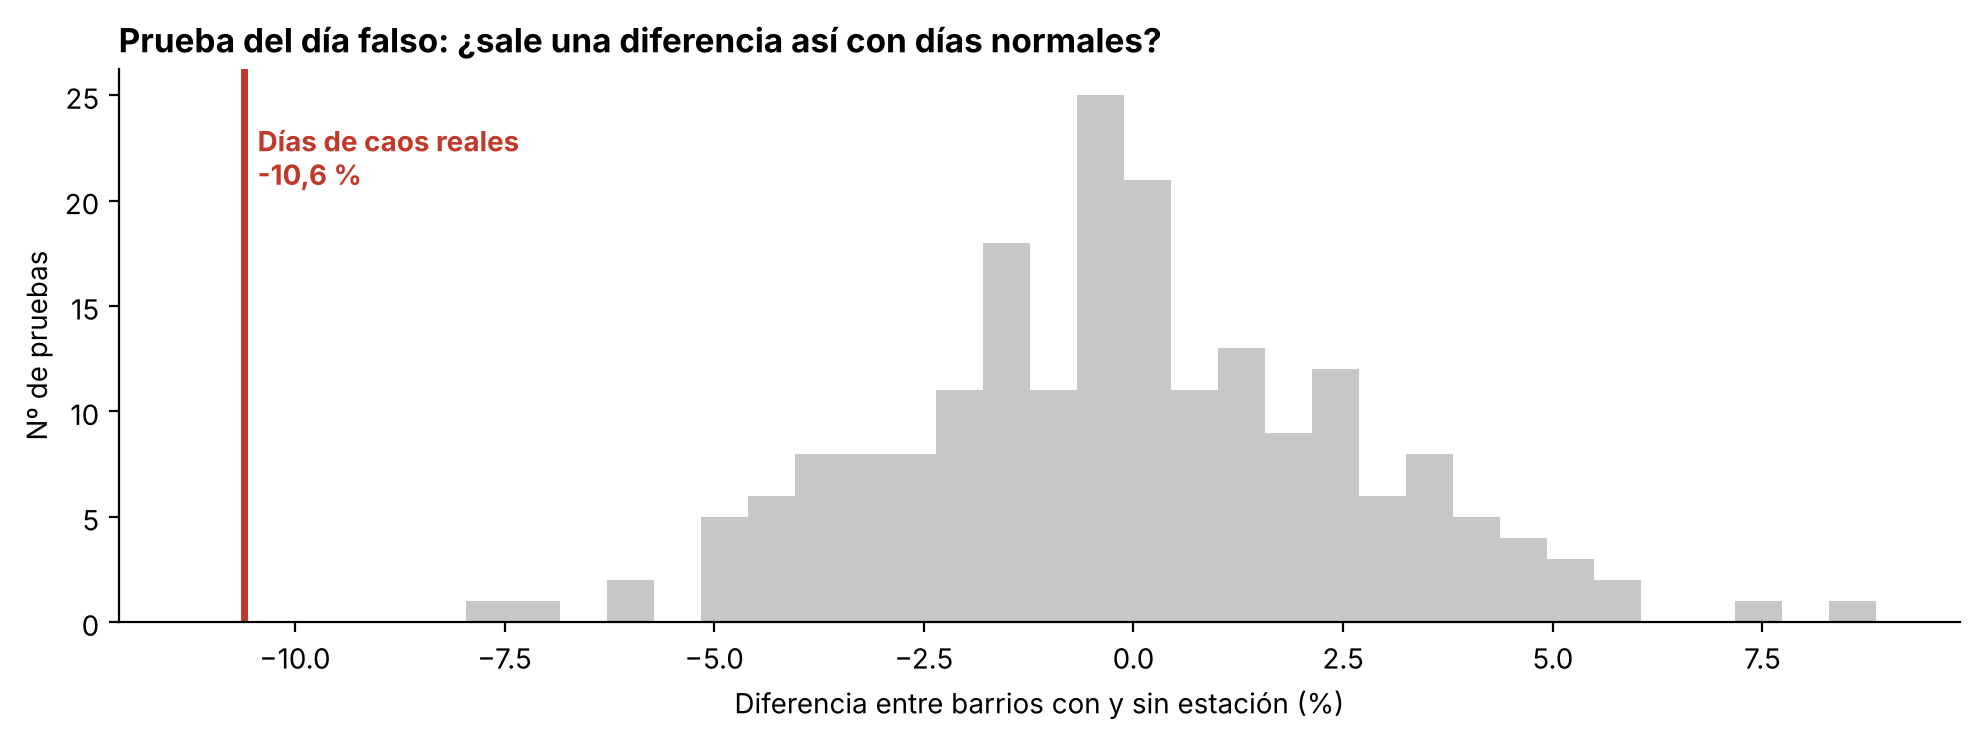

In [16]:
oc, pc = efectos("ida", DEP, caos_real, CON)
os_, ps = efectos("ida", DEP, caos_real, SIN)
real = _pct((oc - os_).mean())
plac_dif = (pc - ps)[np.isfinite(pc - ps)]
grupos_falsos = _pct(np.random.default_rng(0).choice(plac_dif, (200, len(caos_real))).mean(axis=1))
print(f"Diferencia real: {real:+.1f} % · días falsos: 95 % entre {np.percentile(grupos_falsos, 2.5):+.1f} % y "
      f"{np.percentile(grupos_falsos, 97.5):+.1f} % · grupos falsos con una diferencia igual o mayor: "
      f"{(grupos_falsos <= real).sum()} de 200")

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.hist(grupos_falsos, bins=30, color="0.78")
ax.axvline(real, color=ROJO, lw=2.5)
ax.text(real, ax.get_ylim()[1] * .9, f"  Días de caos reales\n  {real:+.1f} %".replace(".", ","), color=ROJO,
        fontweight="bold", ha="left", va="top")
ax.set_xlim(min(real, grupos_falsos.min()) - 1.5, grupos_falsos.max() + 1)
ax.set_xlabel("Diferencia entre barrios con y sin estación (%)")
ax.set_ylabel("Nº de pruebas")
ax.set_title("Prueba del día falso: ¿sale una diferencia así con días normales?", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Resultado.** Con días normales, la diferencia entre barrios con y sin estación es siempre pequeña (el 95 % de los grupos de días falsos, entre −4,9 % y +5,2 %). La de los días de caos reales (**−10,6 %**) queda fuera: **ninguna de las 200 pruebas la alcanza**. La concentración en los barrios con estación no es casualidad.

### 8.2 Comprobación con la regresión

La misma comparación con el segundo método del notebook 03 (diferencias en diferencias, anexo B.2 del 03), adaptado a los
barrios: municipios con ≥ 200 viajes/día hacia cada tipo de barrio y efecto fijo de día × tipo de barrio, para comparar
con el control dentro del mismo tipo de barrio.

In [17]:
def regresion_con_sin(tratados, dias, sentido="ida", min_viajes=200):
    """Diferencias en diferencias por tipo de barrio: efecto hacia barrios con estación, sin estación y diferencia."""
    datos = ida if sentido == "ida" else vuelta
    p = (datos.assign(est=np.where(datos.barrio_destino.isin(CON), "con", "sin"))
         .groupby(["municipio_origen", "est", "fecha"], as_index=False).viajes.sum())
    p = p[p.fecha.isin(limpios.union(dias))]
    media = p[p.fecha.isin(limpios)].groupby(["municipio_origen", "est"]).viajes.mean()
    p = p[pd.MultiIndex.from_frame(p[["municipio_origen", "est"]]).isin(media[media >= min_viajes].index)]
    p = p[p.municipio_origen.isin(set(tratados) | set(CTRL))].copy()
    p["y"] = np.log(p.viajes)
    p["u_dow"] = p.municipio_origen + "_" + p.est + "_" + p.fecha.dt.day_of_week.astype(str)
    caos = p.fecha.isin(dias) & p.municipio_origen.isin(tratados)
    p["trat"], p["trat_con"], p["trat_sin"] = caos.astype(int), (caos & (p.est == "con")).astype(int), (caos & (p.est == "sin")).astype(int)
    vc = {"CRV1": "municipio_origen"}
    m_tipos = pf.feols("y ~ trat_con + trat_sin | u_dow + fecha:est", data=p, vcov=vc)
    m_dif = pf.feols("y ~ trat + trat_con | u_dow + fecha:est", data=p, vcov=vc)
    return {"Con estación %": round(_pct(m_tipos.coef()["trat_con"]), 1), "Sin estación %": round(_pct(m_tipos.coef()["trat_sin"]), 1),
            "Diferencia %": round(_pct(m_dif.coef()["trat_con"]), 1), "Diferencia p": round(m_dif.pvalue()["trat_con"], 3)}


filas = {}
for nombre, dias in [("Media de los 4 días", caos_real)] + [(f"{d:%d/%m/%Y}", [d]) for d in caos_real]:
    c = con_sin("ida", DEP, pd.DatetimeIndex(dias))
    filas[nombre] = {"clustering · con %": c["Con estación"]["cambio_%"], "clustering · sin %": c["Sin estación"]["cambio_%"],
                     "clustering · diferencia %": c["Diferencia"]["cambio_%"], "clustering · p": c["Diferencia"]["p"]} | \
                    {f"regresión · {k}": v for k, v in regresion_con_sin(DEP, pd.DatetimeIndex(dias)).items()}
metodos = pd.DataFrame(filas).T
display(metodos)

,clustering · con %,clustering · sin %,clustering · diferencia %,clustering · p,regresión · Con estación %,regresión · Sin estación %,regresión · Diferencia %,regresión · Diferencia p
Media de los 4 días,-14.6,-4.5,-10.6,0.000,-19.1,2.0,-20.7,0.000
13/05/2024,-24.0,-8.6,-16.9,0.011,-26.7,2.9,-28.8,0.003
17/03/2025,-14.9,-9.5,-6.0,0.176,-18.5,-10.0,-9.5,0.224
26/03/2025,-3.5,5.8,-8.8,0.044,-10.2,5.6,-15.0,0.004
01/04/2025,-14.7,-4.9,-10.3,0.029,-20.3,10.3,-27.8,0.000


**Resultado.** Los dos métodos llegan a la misma conclusión: la caída es mayor hacia los barrios con estación (diferencia clara en la media y los días 13/05, 26/03 y 01/04; no clara el 17/03 con ninguno de los dos). La regresión da caídas mayores hacia los barrios con estación y ninguna hacia el resto (diferencia media de −20,7 %); el clustering es más prudente (−10,6 %). Como en el notebook 03, las cifras que se usan son las del clustering.

---
## 9. Conclusiones

1. **Es el tren.** En los días de caos, los viajes de los municipios dependientes caen sobre todo hacia los barrios de Barcelona con estación de Rodalies (−14,6 %, frente a −4,5 % hacia el resto). A la vuelta pasa lo mismo (−14,2 % frente a −0,7 %). Con días normales no sale nunca una diferencia así.
2. **Confirma el notebook 03 y lo matiza.** Con los mismos días, municipios y método, los datos por barrio dan el mismo resultado. Además muestran que los municipios cercanos sin metro/FGC sí notan el caos (−8,4 % hacia los barrios con estación), aunque en el total apenas se vea.
3. **El aviso cambia la reacción.** En la avería por sorpresa (13/05/2024) la caída es la más fuerte y se concentra en los barrios con estación. En la huelga del 26/03/2025 el total no cambia, pero los viajes se desplazan de los barrios con estación al resto: la gente sigue yendo a Barcelona por otro camino. El 01/04 sí hay caída.
4. **Los barrios que más pierden son los de las grandes estaciones:** Sants, Pl. Catalunya/Pg. de Gràcia, Sant Andreu, Arc de Triomf y Estació de França (entre −15 % y −20 % de media).
5. **Las averías de una línea siguen el mismo patrón** (Gavà: −31 % hacia los barrios con estación a la ida y −62 % a la vuelta). La de la R4 Nord afecta a la ida y no a la vuelta, como una avería de primera hora, pero con muy pocos viajes.
6. **La hora importa.** La avería corta de la tarde del 05/06/2025 no cambia la ida y reduce algo la vuelta (−6,8 %): un indicio de que una avería afecta a los viajes que se hacen mientras dura.

**Limitaciones.** Datos diarios y sin medio de transporte, pocos casos, averías de una línea con solo 4 municipios y muchas comparaciones a la vez (anexo B.3).

---
# B. Anexo técnico

### B.1 Método

Para un grupo de municipios $G$, un conjunto de barrios $B$ y un día $d$:

$$\text{efecto}_{G,B,d} = \frac{V_{G,B}(d) \,/\, \operatorname{mediana}_{r \in R(d)} V_{G,B}(r)}
{V_{C,B}(d) \,/\, \operatorname{mediana}_{r \in R(d)} V_{C,B}(r)} - 1$$

- $V_{G,B}(d)$: viajes de los municipios de $G$ hacia (ida) o desde (vuelta) los barrios de $B$ el día $d$.
- $C$: municipios sin Rodalies (control). $R(d)$: días limpios del mismo año y del mismo tipo que $d$ (clustering del
  notebook 03: K-means con k = 4 sobre el log del volumen del control y la época del año).
- **Diferencia con − sin estación:** $\log(1 + \text{efecto}_{G,\text{con},d}) - \log(1 + \text{efecto}_{G,\text{sin},d})$.
- **p y margen de error:** cada día limpio se trata como un falso día de caos, comparándolo con los días de su tipo en un
  clustering reentrenado sin él (272 placebos). Con varios días, la media se compara con medias de días falsos al azar
  (20.000 simulaciones). p unilateral (¿caída igual o mayor?), como en el notebook 03.
- **Diferencia con el notebook 03:** solo el conjunto de barrios $B$; con $B$ = todos los barrios es el mismo cálculo.

### B.2 Decisiones sobre los datos

- **Filas repetidas:** se suman (notebook 01, sección 3): probablemente son subzonas de los municipios grandes.
- **Barrio de cada estación:** el del punto central de la estación. Las líneas de cada barrio se fijan a mano con la red
  de 2023–2025.
- **Mismos municipios que el notebook 03:** los grupos salen de `municipios_info.parquet` (≥ 200 viajes/día a Barcelona).
  No se aplica ningún umbral adicional por barrio: se suman los viajes del grupo.
- **Vuelta:** viajes con origen en un barrio de Barcelona y destino en otro municipio, el mismo día.

### B.3 Limitaciones

- Los datos por barrio pierden los flujos pequeños (< 15 viajes por par municipio–barrio y día se publican como 0): suman
  ≈ 87 % de los viajes por municipio. Por eso las magnitudes no son idénticas a las del notebook 03.
- Datos diarios y sin medio de transporte: no se sabe a qué hora ni en qué medio se hizo cada viaje.
- Pocos casos: 4 días de caos y 2 averías de una línea con 4 municipios dependientes cada una.
- Muchas comparaciones a la vez (grupos, barrios, días): algún resultado con p ≈ 0,05 puede salir por azar. Se interpretan
  los patrones que se repiten (ida y vuelta, varios días), no un resultado aislado.

### B.4 Exportación para el Observatorio (dashboard)

Guarda en `data/processed/rmove/resultados/barrios_resultados.json` los resultados por barrio que usa el dashboard:
efecto total y hacia barrios con y sin estación (ida y vuelta) para la media de los días de caos y cada día, el contraste
y las averías de una línea. Lo lee `src/dashboard-v2/build_observatorio.py`. Se ejecuta **al final del notebook**.

In [18]:
def _num(x, d=2):
    return None if x is None or not np.isfinite(x) else round(float(x), d)


def fila_json(caso, sentido, r):
    return {"caso": caso, "sentido": sentido,
            "total": _num(r["Total"]["cambio_%"], 1), "total_p": _num(r["Total"]["p"], 4),
            "con_estacion": _num(r["Con estación"]["cambio_%"], 1), "con_estacion_p": _num(r["Con estación"]["p"], 4),
            "sin_estacion": _num(r["Sin estación"]["cambio_%"], 1), "sin_estacion_p": _num(r["Sin estación"]["p"], 4),
            "diferencia": _num(r["Diferencia"]["cambio_%"], 1), "p_diferencia": _num(r["Diferencia"]["p"], 4)}


nombres = {pd.Timestamp("2024-05-13"): "Avería 13/05/2024", pd.Timestamp("2025-03-17"): "Huelga 17/03/2025",
           pd.Timestamp("2025-03-26"): "Huelga 26/03/2025", pd.Timestamp("2025-04-01"): "Huelga 01/04/2025"}
barrios_json = []
for caso, dias in [("Todos los días de caos", caos_real)] + [(nombres[d], [d]) for d in caos_real]:
    for sentido in ("ida", "vuelta"):
        barrios_json.append(fila_json(caso, sentido, con_sin(sentido, DEP, pd.DatetimeIndex(dias))))

averias_json = []
for r in averias.itertuples():
    afect = [c for c in DEP if r.linea in lineas_dep(c)]
    ida_r, vue_r = con_sin("ida", afect, pd.DatetimeIndex([r.fecha])), con_sin("vuelta", afect, pd.DatetimeIndex([r.fecha]))
    averias_json.append({"fecha": f"{r.fecha:%Y-%m-%d}", "linea": r.linea, "titulo": r.descripcion, "municipios": len(afect),
                         "total": _num(ida_r["Total"]["cambio_%"], 1), "total_p": _num(ida_r["Total"]["p"], 4),
                         "ida_con_estacion": _num(ida_r["Con estación"]["cambio_%"], 1),
                         "ida_sin_estacion": _num(ida_r["Sin estación"]["cambio_%"], 1),
                         "vuelta_con_estacion": _num(vue_r["Con estación"]["cambio_%"], 1),
                         "vuelta_sin_estacion": _num(vue_r["Sin estación"]["cambio_%"], 1)})

contraste_json = {"fecha": CASO_CONTRASTE[0], "titulo": CASO_CONTRASTE[1],
                  "ida": fila_json("Contraste", "ida", con_sin("ida", DEP, pd.DatetimeIndex([d_contraste]))),
                  "vuelta": fila_json("Contraste", "vuelta", con_sin("vuelta", DEP, pd.DatetimeIndex([d_contraste])))}

res_barrios = {"fuente": "R-MOVE · movilidad municipio ↔ barrio de Barcelona, notebook 04",
               "metodo": "Clustering del notebook 03 (mismos días, grupos y control), con el control medido hacia el mismo tipo de barrio",
               "barrios": barrios_json, "averias": averias_json, "contraste": contraste_json,
               "duracion_incidencia_larga": None}
destino = OUT / "resultados" / "barrios_resultados.json"
destino.parent.mkdir(parents=True, exist_ok=True)
destino.write_text(json.dumps(res_barrios, ensure_ascii=False, indent=1), encoding="utf-8")
print(f"Guardado: {destino.relative_to(ROOT)} · {len(barrios_json)} filas · {len(averias_json)} averías")
display(pd.DataFrame(barrios_json))

Guardado: data/processed/rmove/resultados/barrios_resultados.json · 10 filas · 2 averías


,caso,sentido,total,total_p,con_estacion,con_estacion_p,sin_estacion,sin_estacion_p,diferencia,p_diferencia
0,Todos los días de caos,ida,-8.9,0.000,-14.6,0.000,-4.5,0.049,-10.6,0.000
1,Todos los días de caos,vuelta,-5.8,0.000,-14.2,0.000,-0.7,0.338,-13.6,0.000
2,Avería 13/05/2024,ida,-14.5,0.007,-24.0,0.004,-8.6,0.051,-16.9,0.011
3,Avería 13/05/2024,vuelta,-12.1,0.004,-21.9,0.004,-5.0,0.099,-17.7,0.004
4,Huelga 17/03/2025,ida,-12.8,0.011,-14.9,0.007,-9.5,0.044,-6.0,0.176
5,Huelga 17/03/2025,vuelta,-6.3,0.029,-15.2,0.004,-0.8,0.454,-14.6,0.007
6,Huelga 26/03/2025,ida,1.8,0.652,-3.5,0.205,5.8,0.894,-8.8,0.044
7,Huelga 26/03/2025,vuelta,-0.5,0.487,-7.4,0.044,3.4,0.751,-10.5,0.018
8,Huelga 01/04/2025,ida,-9.4,0.018,-14.7,0.007,-4.9,0.147,-10.3,0.029
9,Huelga 01/04/2025,vuelta,-4.0,0.132,-11.8,0.004,-0.2,0.498,-11.6,0.015
